# exp_2 / gradcam: where does the full model look?

my mentor suggested two things: check **Grad-CAM**, and check the **heatmaps like in ScoliGaitX** (their Fig. 7). ScoliGaitX shows one heatmap per model variant on a few children and says that the full model "emphasizes the lower back and pelvic regions alongside minors in the head and shoulder regions" (section 5.2.5). there are no numbers behind that sentence: no averaging over children, no check that the heatmap is faithful, no comparison with a random region.

so here i do the same kind of heatmap on my **full** models (not the mini ones), but i also measure it:

1. which body band (head / upper torso / hips / legs) gets how much of the heatmap, per class, over **all 749 test children**, not 3 picked ones
2. is the heatmap on the **left or the right** side of the body, and does that follow the silhouette lean from notebook 08 (`checkpoint_2/self_learning/08_flip_asymmetry`)?
3. which **frames** the model actually uses (max over frames means only some frames reach the head)
4. is the heatmap **faithful** (deleting the hot region should hurt the score more than deleting a random region of the same size) and does it pass the **sanity check** (a model with random top layers should give a different heatmap, Adebayo et al. 2018)

the first model is my ScoNet-MT 16k from checkpoint_1 (official train set). the exp_2 runs (A ... G) are added automatically when their checkpoints are in `output/Scoliosis1K/ScoNetRobust/`.

step 1: setup

In [1]:
import sys
import os
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import cv2
import yaml
from scipy.stats import spearmanr

sys.path.insert(0, os.path.abspath(os.path.join('..', '..', '..', '..', 'self_learning', 'tools')))
from common import *
from common import _opengait_to_mine
sys.path.insert(0, str(REPO / 'opengait'))
from data.transform import DeskewSilCuttingTransform

FIG_DIR = os.path.join('output', 'figures')
CACHE_DIR = os.path.join('output', 'cache')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


the models. every exp_2 run is loaded at `CKPT_ITER` (16k, the paper protocol). when `exp_2/analysis/summary.json` exists i could also take the val-chosen iteration, but for heatmaps one fixed iteration is easier to compare. the input transform comes from the run's config, so the deskew model (G) gets deskewed silhouettes here too.

In [2]:
CKPT_ITER = 16000
EXP2 = REPO / 'checkpoint_2' / 'experiments' / 'exp_2'
RUN_DIR = REPO / 'output' / 'Scoliosis1K' / 'ScoNetRobust'
EXP2_RUNS = ['A_base_s0', 'B_strat_s0', 'D_la_s0', 'E_bam_on_D_la_s0', 'F_ord_on_D_la_s0', 'F_ord_on_B_strat_s0', 'G_deskew_on_D_la_s0', 'L_flip_on_D_la_s0']

MODELS = {'ScoNet-MT 16k': {'ckpt': SCONET_16K, 'transform': 'BaseSilCuttingTransform'}}
for run in EXP2_RUNS:
    ck = RUN_DIR / run / 'checkpoints' / f'{run}-{CKPT_ITER:05d}.pt'
    if ck.exists():
        cfg = yaml.safe_load(open(EXP2 / 'configs' / f'{run}.yaml'))
        MODELS[run] = {'ckpt': ck, 'transform': cfg['evaluator_cfg']['transform'][0]['type']}
print('models found:', list(MODELS))


def load_opengait(path):
    # OpenGait checkpoint (ScoNet or ScoNetRobust) -> my ScoNetMT; auxiliary heads are not needed for the heatmaps
    sd = torch.load(path, map_location='cpu', weights_only=False)['model']
    mine = {}
    for k, v in sd.items():
        if k.startswith('Backbone.'):
            mine['backbone.' + _opengait_to_mine(k)] = v
        elif k.startswith('FCs.'):
            mine[k.replace('FCs.', 'fcs.')] = v
        elif k.startswith('BNNecks.'):
            mine[k.replace('BNNecks.', 'bnnecks.')] = v
    model = ScoNetMT()
    model.load_state_dict(mine)
    return model.to(DEVICE).eval()


DESKEW = DeskewSilCuttingTransform()


def input_transform(seq, name):
    # seq uint8 [s, 64, 64] -> float [s, 64, 44], the same as the OpenGait evaluator of that run
    if name == 'DeskewSilCuttingTransform':
        return DESKEW(seq).astype(np.float32)
    return sil_transform(seq)

models found: ['ScoNet-MT 16k']


the test children: the official test split (204 negative / 126 neutral / 419 positive), the same 749 as in every full run. every child is tested with **all its frames**, like OpenGait `--phase test`, because these are full models (the clip trick of the mini notebooks is not needed here).

In [3]:
TEST_CHILDREN = sorted(load_split('118')['TEST_SET'])
TEST_CLASS = {s: subject_class(s) for s in TEST_CHILDREN}
print('test children:', len(TEST_CHILDREN), {c: sum(v == c for v in TEST_CLASS.values()) for c in LABEL_NAMES})

test children: 749 {'negative': 204, 'neutral': 126, 'positive': 419}


step 2: Grad-CAM on the pooled feature map

how ScoNet decides: every frame goes alone through ResNet9 and gives a map `[512, 16, 11]`, the max over frames gives **one** map `A` `[512, 16, 11]`, and the 16 strips of `A` go to the head. so the natural place for Grad-CAM is `A`, the last map before the head:

- `w_k = mean over (h, w) of d target / d A_k` (one weight per channel)
- `CAM = ReLU(sum_k w_k A_k)` -> `[16, 11]`, upsampled to the silhouette size `64 x 44`

a nice side effect: the backbone can run under `no_grad` (300 frames, cheap), and only the small head needs a gradient.

two targets:
- **true class**: the logit of the child's real class (what ScoliGaitX shows)
- **scoliosis evidence**: `logsumexp(z_neu, z_pos) - z_neg`, "how much more scoliosis than healthy". this is the decision the lean from notebook 08 seems to drive, so it is the one i measure in steps 4-7.

In [4]:
@torch.no_grad()
def frame_features(model, sils, chunk=100):
    # sils float [s, 64, 44] -> per-frame maps [s, 512, 16, 11]
    out = []
    x = torch.tensor(sils)
    for part in torch.split(x, chunk):
        with torch.autocast(device_type=DEVICE, enabled=DEVICE == 'cuda'):
            out.append(model.backbone(part[:, None].to(DEVICE)).float())
    return torch.cat(out)


def head_scores(model, pooled):
    # pooled [1, 512, 16, 11] -> z [1, 3] = 16 * mean-over-strips logits (the ScoNet decision score)
    logits = model.bnnecks(model.fcs(horizontal_pooling(pooled)))
    return 16 * logits.mean(-1)


TARGETS = {
    'true class': lambda z, y: z[0, y],
    'scoliosis evidence': lambda z, y: torch.logsumexp(z[0, 1:], 0) - z[0, 0],
}


def grad_cam(model, pooled, target, y):
    A = pooled.clone().requires_grad_(True)
    z = head_scores(model, A)
    t = TARGETS[target](z, y)
    g, = torch.autograd.grad(t, A)
    w = g.mean((2, 3), keepdim=True)
    term = w * A                                    # [1, 512, 16, 11]
    cam = F.relu(term.sum(1))[0]
    return cam.detach().cpu().numpy(), z.detach().cpu().numpy()[0], F.relu(term)[0].detach()


def upsample(cam, size=(44, 64)):
    return cv2.resize(cam.astype(np.float32), size, interpolation=cv2.INTER_LINEAR)

step 3: one pass over all test children

for every child i keep: the decision scores `z`, both CAMs, the GEI (mean silhouette, for the overlays and the body mask), the per-frame contribution (step 6) and the frame width (a view proxy: narrow = front / back, wide = side). the result is cached in `output/cache/<model>.npz`, so re-running the notebook doesn't redo it.

**frame contribution**: after the max over frames, every position `(k, h, w)` of `A` comes from exactly one frame. i give that frame the positive Grad-CAM term `ReLU(w_k A_khw)` of the position. summed over positions, this says how much each frame feeds the scoliosis-evidence heatmap.

In [5]:
def child_pass(model, subject, transform_name):
    seq = load_seq(subject, TEST_CLASS[subject])
    sils = input_transform(seq, transform_name)
    y = LABELS[TEST_CLASS[subject]]
    f = frame_features(model, sils)                          # [s, 512, 16, 11]
    pooled, arg = f.max(0)
    pooled = pooled[None]
    cam_true, z, _ = grad_cam(model, pooled, 'true class', y)
    cam_sco, _, term = grad_cam(model, pooled, 'scoliosis evidence', y)
    contrib = torch.zeros(len(sils), device=term.device).index_add_(0, arg.flatten(), term.flatten())
    width = (sils.sum(1) > 0).sum(-1)                         # body width per frame, in columns
    return {'z': z, 'y': y, 'cam_true': cam_true, 'cam_sco': cam_sco, 'gei': sils.mean(0),
            'contrib': contrib.cpu().numpy(), 'width': width}


def run_all(name, info):
    path = os.path.join(CACHE_DIR, name.replace(' ', '_') + '.npz')
    if os.path.exists(path):
        d = np.load(path, allow_pickle=True)
        return {k: d[k] for k in d.files}
    model = load_opengait(info['ckpt'])
    rows = []
    t = time.time()
    for s in TEST_CHILDREN:
        rows.append(child_pass(model, s, info['transform']))
    res = {k: np.stack([r[k] for r in rows]) for k in ['z', 'y', 'cam_true', 'cam_sco', 'gei']}
    res['contrib'] = np.array([r['contrib'] for r in rows], dtype=object)
    res['width'] = np.array([r['width'] for r in rows], dtype=object)
    res['subject'] = np.array(TEST_CHILDREN)
    np.savez(path, **res)
    print(f'{name}: {len(rows)} children in {time.time() - t:.0f}s')
    return res


RES = {name: run_all(name, info) for name, info in MODELS.items()}
for name, r in RES.items():
    m = metrics(r['y'], r['z'].argmax(-1))
    print(f"{name:22s} acc {m['acc']:.1f}  Sen {m['Sen']:.1f}  Spe {m['Spe']:.1f}  neutral recall {m['rec_neu']:.1f}")

ScoNet-MT 16k          acc 82.6  Sen 98.5  Spe 77.8  neutral recall 40.5


**check**: the ScoNet-MT 16k numbers have to be the ones OpenGait printed for this checkpoint (82.6 / 98.5 / 77.8, memory of checkpoint_1). if they are, my forward pass is the same as OpenGait's, and the heatmaps belong to the real model.

step 4: heatmaps like ScoliGaitX Fig. 7, and the class averages

first the ScoliGaitX-style picture: three correctly classified children per class, GEI with the true-class CAM on top. then the thing ScoliGaitX doesn't show: the **average CAM of all test children of a class**. the silhouettes are already centred and scaled by the pretreatment, so the pixel positions line up between children and an average is meaningful.

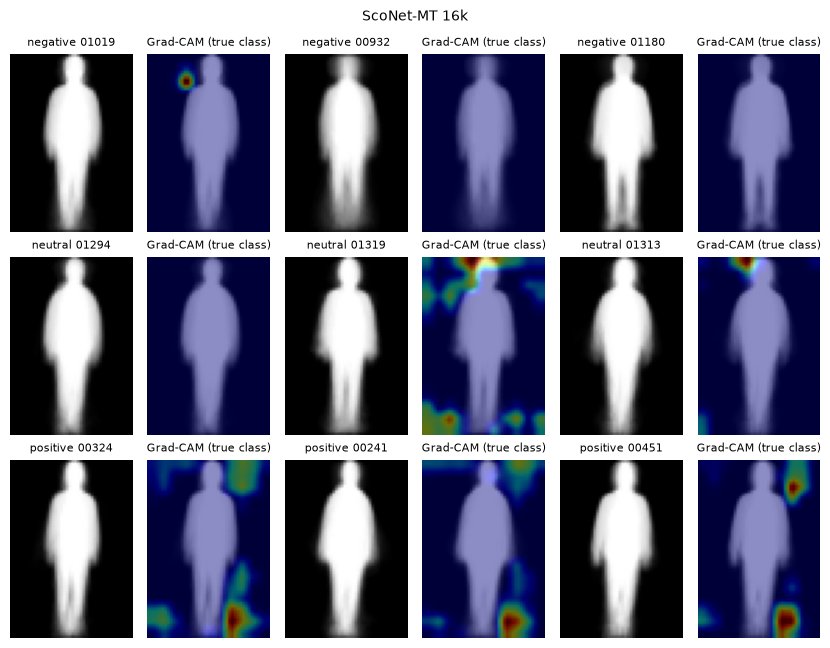

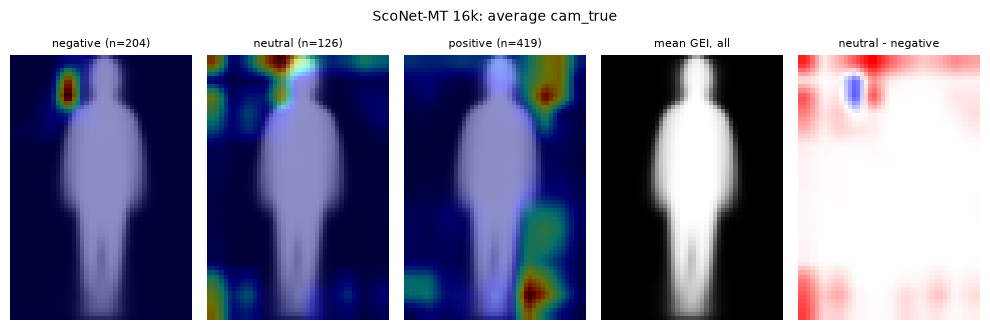

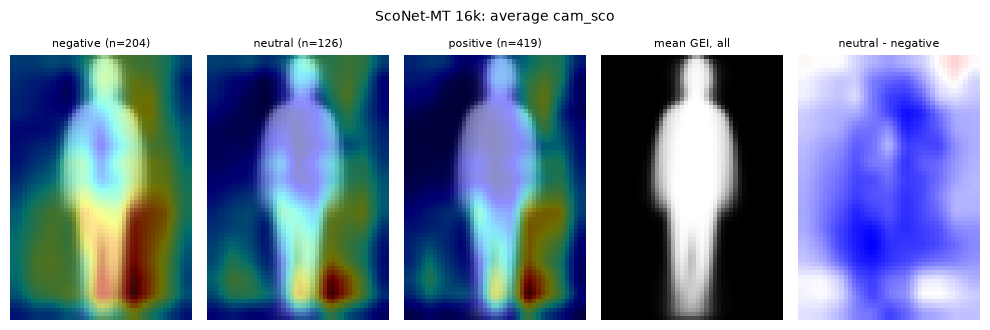

In [6]:
def overlay(ax, gei, cam, title=''):
    c = upsample(cam)
    c = c / (c.max() + 1e-8)
    ax.imshow(gei, cmap='gray', vmin=0, vmax=1)
    ax.imshow(c, cmap='jet', alpha=0.45, vmin=0, vmax=1)
    ax.set_title(title, fontsize=8)
    ax.axis('off')


def examples_figure(name, r, per_class=3, seed=0):
    rng = np.random.default_rng(seed)
    pred = r['z'].argmax(-1)
    fig, axes = plt.subplots(3, per_class * 2, figsize=(per_class * 2 * 1.4, 3 * 2.2))
    for c in range(3):
        idx = np.where((r['y'] == c) & (pred == c))[0]
        pick = rng.choice(idx, min(per_class, len(idx)), replace=False)
        for j, i in enumerate(pick):
            axes[c, 2 * j].imshow(r['gei'][i], cmap='gray')
            axes[c, 2 * j].set_title(f"{LABEL_NAMES[c]} {r['subject'][i]}", fontsize=8)
            axes[c, 2 * j].axis('off')
            overlay(axes[c, 2 * j + 1], r['gei'][i], r['cam_true'][i], 'Grad-CAM (true class)')
    fig.suptitle(name, fontsize=10)
    save_and_show(fig, f"examples_{name.replace(' ', '_')}.png")


def class_average_figure(name, r, key='cam_true'):
    fig, axes = plt.subplots(1, 5, figsize=(10, 3.4))
    means = []
    for c in range(3):
        cams = np.stack([upsample(x) / (x.max() + 1e-8) for x in r[key][r['y'] == c]])
        means.append(cams.mean(0))
        overlay(axes[c], r['gei'][r['y'] == c].mean(0), means[-1], f'{LABEL_NAMES[c]} (n={len(cams)})')
    axes[3].imshow(r['gei'].mean(0), cmap='gray')
    axes[3].set_title('mean GEI, all', fontsize=8)
    axes[3].axis('off')
    diff = means[1] - means[0]
    v = np.abs(diff).max()
    axes[4].imshow(diff, cmap='bwr', vmin=-v, vmax=v)
    axes[4].set_title('neutral - negative', fontsize=8)
    axes[4].axis('off')
    fig.suptitle(f'{name}: average {key}', fontsize=10)
    save_and_show(fig, f"class_average_{key}_{name.replace(' ', '_')}.png")


for name, r in RES.items():
    examples_figure(name, r)
    class_average_figure(name, r, 'cam_true')
    class_average_figure(name, r, 'cam_sco')

**what i see (ScoNet-MT 16k):**

- the check passes: 82.6 / 98.5 / 77.8, neutral recall 40.5, the same numbers OpenGait printed. the heatmaps belong to the real model.
- **the single-child heatmaps don't look like ScoliGaitX's.** the hot spots sit mostly **outside the body**: in the background right of the feet, in the top corners and next to the head. with the true-class target, many maps are completely empty (step 5: 57% of negatives). Grad-CAM's ReLU removes everything when the weighted channels add up to a negative number, which is a known weakness of Grad-CAM. ScoliGaitX doesn't say whether this happened to them.
- **the class averages say the same.** the scoliosis-evidence map is strongest in the empty area right of the lower legs and feet, in all three classes. the "neutral - negative" map is blue almost everywhere: neutral children get *less* evidence in nearly every pixel, with no region where they get more. that fits the 97% of missed neutrals that go to negative: the model has no place where it sees a neutral child.
- the body itself (torso, hips) is the coolest part of the map. this is the opposite of the ScoliGaitX sentence about the "lower back and pelvic regions".

step 5: how much heatmap falls in each body band

the same four bands as notebook 08 (rows of the 64-pixel silhouette): head 0-10, upper torso 10-24, hips 24-36, legs 36-64. for each child i normalise the upsampled scoliosis-evidence CAM to sum 1 and add up each band. a **uniform** heatmap over the body would give each band its share of the body pixels, so i also print that "body share" from the GEI: a band only gets real attention if its CAM share is clearly above its body share.

i also split the neutrals into the ones the model got right and the ones it missed (97% of the missed neutrals go to negative, memory of 2026-11-15): do the missed ones get a different heatmap?

In [7]:
BANDS = {'head': (0, 10), 'upper torso': (10, 24), 'hips': (24, 36), 'legs': (36, 64)}


def band_shares(maps):
    # maps [n, 64, 44] non-negative -> [n, bands], every row sums to 1
    tot = maps.sum((1, 2)) + 1e-8
    return np.stack([maps[:, a:b].sum((1, 2)) / tot for a, b in BANDS.values()], 1)


def band_table(name, r, key='cam_sco'):
    cams = np.stack([upsample(x) for x in r[key]])
    cam_share = 100 * band_shares(cams)
    body_share = 100 * band_shares(r['gei'])
    pred = r['z'].argmax(-1)
    groups = {LABEL_NAMES[c]: r['y'] == c for c in range(3)}
    groups['neutral, correct'] = (r['y'] == 1) & (pred == 1)
    groups['neutral, missed'] = (r['y'] == 1) & (pred != 1)
    print(f'{name} | {key} share per band (%), body share in brackets')
    print(f'{"":18s}' + ''.join(f'{b:>20s}' for b in BANDS))
    for g, mask in groups.items():
        cells = ''.join(f'{cam_share[mask, i].mean():11.1f} ({body_share[mask, i].mean():4.1f})  ' for i in range(len(BANDS)))
        print(f'{g:18s}{cells}   n={mask.sum()}')
    return cam_share, body_share


SHARES = {name: band_table(name, r) for name, r in RES.items()}


def inside_body(name, r):
    # how much of the heatmap is on the body at all (GEI > 0.1), and how often Grad-CAM is completely empty
    body_area = np.mean([(g > 0.1).mean() for g in r['gei']])
    print(f'{name} | body = {100 * body_area:.1f}% of the image')
    for key in ['cam_true', 'cam_sco']:
        cams = np.stack([upsample(x) for x in r[key]])
        empty = r[key].reshape(len(cams), -1).max(1) <= 1e-6
        inside = np.array([(c * (g > 0.1)).sum() / (c.sum() + 1e-8) for c, g in zip(cams, r['gei'])])
        print(f'  {key:9s} empty CAM: ' + ', '.join(f'{LABEL_NAMES[c]} {100 * empty[r["y"] == c].mean():.0f}%' for c in range(3)) +
              ' | share inside the body: ' + ', '.join(f'{LABEL_NAMES[c]} {100 * inside[(r["y"] == c) & ~empty].mean():.0f}%' for c in range(3)))


for name, r in RES.items():
    inside_body(name, r)

ScoNet-MT 16k | cam_sco share per band (%), body share in brackets
                                  head         upper torso                hips                legs
negative                 12.2 ( 9.0)         15.5 (28.0)         18.0 (29.0)         54.3 (34.0)     n=204
neutral                  15.7 ( 9.0)         10.8 (28.0)         15.0 (29.2)         58.5 (33.8)     n=126
positive                 14.7 ( 9.0)         11.2 (28.3)         13.5 (29.1)         60.5 (33.6)     n=419
neutral, correct         18.2 ( 9.1)          8.1 (28.4)         12.7 (29.3)         61.0 (33.2)     n=51
neutral, missed          14.0 ( 9.0)         12.7 (27.8)         16.5 (29.0)         56.8 (34.2)     n=75
ScoNet-MT 16k | body = 34.7% of the image
  cam_true  empty CAM: negative 57%, neutral 21%, positive 8% | share inside the body: negative 12%, neutral 18%, positive 8%
  cam_sco   empty CAM: negative 0%, neutral 0%, positive 0% | share inside the body: negative 40%, neutral 30%, positive 28%


**what i see:**

- **legs and feet take 54-61% of the heatmap**, although they are only 34% of the body rows. the head gets a little more than its share (12-18 vs 9). **upper torso (11-16 vs 28) and hips (14-18 vs 29) get about half their share**. so the band where the clinical sign should be, the shoulders and trunk, is the one the model uses least.
- **only 28-40% of the scoliosis-evidence heatmap is on the body at all, and the body covers 35% of the image.** for positive children (28%) the heatmap is *less* on the body than a uniform map would be. the bands above therefore mostly measure background next to each band, not the body part.
- the true-class Grad-CAM is completely empty for 57% of negatives, 21% of neutrals and 8% of positives.
- correct vs missed neutrals: the correct ones have even more head and legs (18 / 61) and less torso (8). so the model doesn't get a neutral right by looking at the trunk either.

step 6: left / right, and the lean of notebook 08

notebook 08 found that the silhouettes lean (head image-right, legs image-left), more for neutral and positive, and that the model's score follows that lean even inside healthy children. if the model uses the lean, the heatmap should not be left/right symmetric. for each child:

- **CAM side** = (CAM mass right of the body centre - left) / total, centre = centre of mass of the GEI
- **silhouette lean** = the signed upper-torso asymmetry of notebook 08 (on the GEI here, which is the mean of the frames)

then the Spearman correlation of the scoliosis evidence and of the CAM side with the lean, **inside the negative children only** (they have no curve, so any link there is not the disease).

In [8]:
def lr_side(maps, geis):
    out = []
    cols = np.arange(geis.shape[-1])
    for m, g in zip(maps, geis):
        cx = (g.sum(0) * cols).sum() / (g.sum() + 1e-8)
        out.append((m[:, cols > cx].sum() - m[:, cols < cx].sum()) / (m.sum() + 1e-8))
    return np.array(out)


def torso_lean(geis):
    # signed upper-torso asymmetry of notebook 08, around the centre column of the whole body
    a, b = BANDS['upper torso']
    cols = np.arange(geis.shape[-1])
    out = []
    for g in geis:
        cx = (g.sum(0) * cols).sum() / (g.sum() + 1e-8)
        band = g[a:b]
        out.append((band[:, cols > cx].sum() - band[:, cols < cx].sum()) / (band.sum() + 1e-8))
    return np.array(out)


def side_analysis(name, r):
    cams = np.stack([upsample(x) for x in r['cam_sco']])
    side = lr_side(cams, r['gei'])
    lean = torso_lean(r['gei'])
    evidence = np.logaddexp(r['z'][:, 1], r['z'][:, 2]) - r['z'][:, 0]
    print(f'{name}')
    print(f'{"":10s}{"CAM side x100":>16s}{"lean x100":>12s}{"rho(evidence, lean)":>22s}{"rho(CAM side, lean)":>22s}')
    for c in range(3):
        m = r['y'] == c
        print(f'{LABEL_NAMES[c]:10s}{100 * side[m].mean():16.1f}{100 * lean[m].mean():12.1f}'
              f'{spearmanr(evidence[m], lean[m])[0]:22.2f}{spearmanr(side[m], lean[m])[0]:22.2f}')
    print(f'AUC scoliosis vs negative: model evidence {100 * auc(evidence[r["y"] > 0], evidence[r["y"] == 0]):.1f}, '
          f'lean alone {100 * auc(lean[r["y"] > 0], lean[r["y"] == 0]):.1f}')
    return side, lean, evidence


SIDES = {name: side_analysis(name, r) for name, r in RES.items()}

ScoNet-MT 16k
             CAM side x100   lean x100   rho(evidence, lean)   rho(CAM side, lean)
negative              18.8         4.7                  0.38                  0.63
neutral               31.4         7.6                  0.20                  0.29
positive              44.7         6.0                  0.19                  0.34
AUC scoliosis vs negative: model evidence 97.5, lean alone 67.5


**what i see:**

- **the heatmap is strongly one-sided.** the CAM side is +19 (negative), +31 (neutral) and +45 (positive), so it lies on the image-right of the body, more for scoliosis. the silhouette lean has the same order.
- **inside the healthy children, the heatmap side follows the lean: rho 0.63.** the scoliosis evidence follows it with rho 0.38. this is the full 16k model, and the value matches notebook 08's mini models (0.32-0.44). so the lean link is not a mini-model artefact.
- the model's evidence separates scoliosis from negative with AUC 97.5, and the GEI lean alone gives 67.5 (notebook 08 got 81 with the per-frame version). so the model clearly uses more than the lean, but the part of its heatmap we can see is tied to the lean.

step 7: which frames feed the heatmap

with the frame contribution of step 3 i can see if the model's evidence comes from a few frames or from all of them, and which view: the frame width is small when the child walks towards / away from the camera and large at the turn (side view). i correlate contribution with width inside each child and plot the average contribution against the width rank.

ScoNet-MT 16k: share of the evidence from the top 10% frames 25.6% (uniform would be 10%), rho(contribution, width) median 0.07


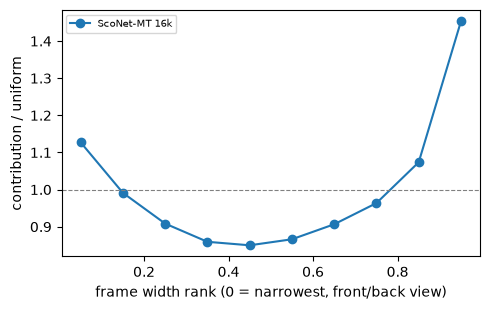

In [9]:
def frame_analysis(name, r, bins=10):
    rhos, top10, curves = [], [], []
    for c, w in zip(r['contrib'], r['width']):
        c = np.asarray(c, dtype=float)
        w = np.asarray(w, dtype=float)
        if c.sum() <= 0 or w.std() == 0:
            continue
        p = c / c.sum()
        rhos.append(spearmanr(p, w)[0])
        top10.append(np.sort(p)[::-1][:max(1, len(p) // 10)].sum())
        rank = np.argsort(np.argsort(w)) / (len(w) - 1)
        curves.append([p[(rank >= a) & (rank <= a + 1 / bins)].mean() * len(p) for a in np.linspace(0, 1 - 1 / bins, bins)])
    print(f'{name}: share of the evidence from the top 10% frames {100 * np.mean(top10):.1f}% '
          f'(uniform would be 10%), rho(contribution, width) median {np.median(rhos):.2f}')
    return np.nanmean(np.array(curves), 0)


fig, ax = plt.subplots(figsize=(5, 3.2))
for name, r in RES.items():
    curve = frame_analysis(name, r)
    ax.plot(np.linspace(0.05, 0.95, len(curve)), curve, marker='o', label=name)
ax.axhline(1, color='gray', ls='--', lw=0.8)
ax.set_xlabel('frame width rank (0 = narrowest, front/back view)')
ax.set_ylabel('contribution / uniform')
ax.legend(fontsize=7)
save_and_show(fig, 'frame_contribution_vs_width.png')

**what i see:**

- the evidence is concentrated: **the top 10% of frames give 25.6% of it** (uniform would be 10%). max pooling makes this expected.
- **frame width doesn't matter** (median rho 0.07, flat curve). the model doesn't prefer the front/back frames or the side-view frames at the turn. so a view-specific design (view bags) has no support from this model.

step 8: is the heatmap faithful, and does it pass the sanity check?

a heatmap is only worth showing if it says something about the model. two checks on a subset (40 children per class, fixed seed):

1. **deletion**: set the top 15% CAM pixels inside the body (GEI > 0.1) to 0 in **every frame**, and measure the drop of the scoliosis evidence. compare with deleting a **random** 15% of the body pixels (3 draws). faithful = the CAM deletion hurts clearly more.
2. **model randomisation** (Adebayo et al., "Sanity checks for saliency maps", 2018): re-initialise the head (SeparateFCs + BNNeck) and layer4 at random and recompute the CAM. a heatmap that still looks the same would just be an edge detector of the silhouette. i report the Spearman rank correlation between the real and the random-model CAM.

In [10]:
@torch.no_grad()
def evidence_of(model, sils):
    f = frame_features(model, sils).max(0)[0][None]
    z = head_scores(model, f)[0]
    return (torch.logsumexp(z[1:], 0) - z[0]).item()


def deletion_test(name, info, r, per_class=40, frac=0.15, n_random=3, seed=0):
    model = load_opengait(info['ckpt'])
    rng = np.random.default_rng(seed)
    pick = np.concatenate([rng.choice(np.where(r['y'] == c)[0], per_class, replace=False) for c in range(3)])
    drops_cam, drops_rand = [], []
    for i in pick:
        s = r['subject'][i]
        sils = input_transform(load_seq(s, TEST_CLASS[s]), info['transform'])
        body = r['gei'][i] > 0.1
        cam = upsample(r['cam_sco'][i])
        k = int(frac * body.sum())
        order = np.argsort(np.where(body, cam, -np.inf).ravel())[::-1][:k]
        base = evidence_of(model, sils)
        mask = np.ones(body.size, np.float32)
        mask[order] = 0
        drops_cam.append(base - evidence_of(model, sils * mask.reshape(body.shape)))
        body_idx = np.where(body.ravel())[0]
        d = []
        for _ in range(n_random):
            mask = np.ones(body.size, np.float32)
            mask[rng.choice(body_idx, k, replace=False)] = 0
            d.append(base - evidence_of(model, sils * mask.reshape(body.shape)))
        drops_rand.append(np.mean(d))
    drops_cam, drops_rand = np.array(drops_cam), np.array(drops_rand)
    y = r['y'][pick]
    print(f'{name}: drop of the scoliosis evidence after deleting {int(100 * frac)}% of the body pixels')
    for c in range(3):
        m = y == c
        print(f'  {LABEL_NAMES[c]:9s} CAM region {drops_cam[m].mean():+6.2f}   random region {drops_rand[m].mean():+6.2f}   '
              f'CAM > random in {100 * np.mean(drops_cam[m] > drops_rand[m]):.0f}% of children')
    return drops_cam, drops_rand, y


def randomisation_test(name, info, r, n=60, seed=0):
    model = load_opengait(info['ckpt'])
    rand = load_opengait(info['ckpt'])
    torch.manual_seed(seed)
    for mod in [rand.backbone.layer4, rand.fcs, rand.bnnecks]:
        init_parameters(mod)
    rng = np.random.default_rng(seed)
    pick = rng.choice(len(r['y']), n, replace=False)
    rhos = []
    for i in pick:
        s = r['subject'][i]
        sils = input_transform(load_seq(s, TEST_CLASS[s]), info['transform'])
        pooled = frame_features(rand, sils).max(0)[0][None]
        cam_r, _, _ = grad_cam(rand, pooled, 'scoliosis evidence', int(r['y'][i]))
        rhos.append(spearmanr(r['cam_sco'][i].ravel(), cam_r.ravel())[0])
    print(f'{name}: rank correlation real vs randomised-model CAM, median {np.nanmedian(rhos):.2f} '
          f'(1 = the heatmap ignores the learned weights)')
    return np.array(rhos)


FAITH = {name: deletion_test(name, info, RES[name]) for name, info in MODELS.items()}
SANITY = {name: randomisation_test(name, info, RES[name]) for name, info in MODELS.items()}

ScoNet-MT 16k: drop of the scoliosis evidence after deleting 15% of the body pixels
  negative  CAM region  -0.86   random region  -0.43   CAM > random in 22% of children
  neutral   CAM region  +0.41   random region  +0.46   CAM > random in 42% of children
  positive  CAM region  +1.02   random region  +1.29   CAM > random in 32% of children


ScoNet-MT 16k: rank correlation real vs randomised-model CAM, median 0.01 (1 = the heatmap ignores the learned weights)


**what i see:**

- **sanity check: passed.** the randomised-model heatmap has rank correlation 0.01 with the real one, so the heatmap depends on the learned weights and is not just an edge detector.
- **faithfulness: failed.** deleting the 15% hottest body pixels lowers the scoliosis evidence **less** than deleting a random 15%. CAM beats random in only 22% (negative), 42% (neutral) and 32% (positive) of the children. for negatives, deleting the CAM region even *raises* the evidence (-0.86 vs -0.43).
- so Grad-CAM points at regions that depend on the weights, but on the body they are not the regions the decision depends on. two reasons fit. (1) most of the heatmap lies off the body, where deletion can't act, so the in-body top-15% is the weak tail of the map. (2) the max over frames re-routes when pixels are deleted, because another frame becomes the max.

step 9: analysis

**1. does the full ScoNet-MT look at the body region ScoliGaitX describes (pelvis, lower back, shoulders)?**

no. averaged over 749 children, the scoliosis-evidence heatmap is mostly off the body (only 28-40% on it, against 35% for a uniform map). inside the body it prefers legs/feet and head; torso and hips get about half their share. ScoliGaitX's Fig. 7 is 5 qualitative pictures with no averaging and no faithfulness test, so it can't show a different result. but we can't say their model behaves like ours either, because we didn't run their model.

**2. what does the heatmap follow, then?**

the side of the body and the lean. the heatmap is on the image-right, more for scoliosis, and inside healthy children its side correlates with the silhouette lean at rho 0.63. together with notebook 08, the explanation that fits best: ScoNet reads the **position of the silhouette in the frame** (empty space right of the feet, tilt of the head and legs), and that position varies with the recording block.

**3. can we trust these heatmaps?**

only partly. they pass the randomisation sanity check, but they fail the deletion test. **so a heatmap figure alone must not be used as evidence that a model "looks at the spine".** any heatmap claim in my paper should come with the deletion numbers. ScoliGaitX has none.

**4. which frames?**

a quarter of the evidence comes from 10% of the frames, and the view (frame width) plays no role.

**limitations**

- one model (ScoNet-MT 16k, one seed, full train set). the exp_2 runs are added automatically when their checkpoints arrive. the most interesting comparison is **G_deskew vs D_la**: does removing the lean move the heatmap onto the body, and what does it cost in AUC?
- Grad-CAM on a 16 x 11 map is coarse: one cell is about 4 x 4 pixels.
- the bands are fixed image rows, not detected body parts.
- deleting pixels from a silhouette changes its shape and makes an out-of-distribution input. a softer deletion (blur, or deleting in feature space) would be a useful second check.

**what can we absorb into the new architecture / paper?**

- the "robust" claim should be measured, not shown: **in-body heatmap share, deletion-vs-random, rho(heatmap side, lean) inside negatives**, reported for every exp_2 variant next to AUC. a robust model should have a higher in-body share and a lower lean correlation at a similar AUC.
- `G_deskew` is the direct test. if its AUC stays near D_la while the lean correlation drops, that is a real result no competitor reports.
- the "neutral - negative" map is blue everywhere: the model has no region where it sees neutral. that supports an explicit neutral/ordinal head (E / F) over more threshold tuning.